# Prédiction des salaires dans la tech — analyse complète

Exploration, analyse statistique, inférence causale et modèles de machine learning (XGBoost, LightGBM, CatBoost) sur 250 000 profils.

Le code réutilisable vit dans le package `salary` (`src/salary/`). Ce notebook raconte l'analyse et s'appuie sur ce package et sur les artefacts produits par `python -m salary.stats`, `python -m salary.causal` et `python -m salary.train`.

## À propos du jeu de données
This dataset contains 250,000 job records designed for salary prediction, data analysis, and machine learning projects.

It includes information about job titles, experience level, education background, skills, industry type, company size, and work location. The dataset helps researchers and data scientists explore how different factors influence salary.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Dictionnaire des données

| Colonne | Type | Description |
|---|---|---|
| `job_title` | Texte | Intitulé du poste (ex : Data Analyst, AI Engineer) |
| `experience_years` | Entier | Nombre d'années d'expérience professionnelle |
| `education_level` | Texte | Niveau d'études le plus élevé obtenu |
| `skills_count` | Entier | Nombre de compétences techniques |
| `industry` | Texte | Secteur d'activité |
| `company_size` | Texte | Taille de l'entreprise (Small / Medium / Large) |
| `location` | Texte | Localisation du poste |
| `remote_work` | Texte | Mode de travail (Yes / No / Hybrid) |
| `certifications` | Entier | Nombre de certifications professionnelles |
| `salary` | Entier | **Variable cible** — salaire annuel |

In [2]:
df_job_salary_prediction = pd.read_csv('../data/raw/job_salary_prediction_dataset.csv')

In [3]:
df_job_salary_prediction.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


## 1. Préparation

On réutilise la configuration du projet : chemins, ordre des modalités ordinales, graine 42. Ainsi, le notebook et l'application partagent exactement les mêmes définitions.

In [4]:
import json
import warnings

import numpy as np
import seaborn as sns
from scipy import stats as st

from salary import config as cfg
from salary import stats as sstats
from salary.data import validate

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
L = cfg.LABELS_FR

df = df_job_salary_prediction.copy()
df = validate(df)  # colonnes, valeurs manquantes, modalités et plages
print(df.shape)

(250000, 10)


## 2. Qualité des données

In [5]:
quality = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs manquantes": df.isna().sum(),
    "modalités distinctes": df.nunique(),
})
print(f"Doublons : {df.duplicated().sum()}")
quality

Doublons : 0


,type,valeurs manquantes,modalités distinctes
job_title,str,0,12
experience_years,int64,0,21
education_level,str,0,5
skills_count,int64,0,19
industry,str,0,10
company_size,str,0,5
location,str,0,10
remote_work,str,0,3
certifications,int64,0,6
salary,int64,0,118956


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
experience_years,"250,000.0000",10.0054,6.0606,0.0000,5.0000,10.0000,15.0000,20.0000
skills_count,"250,000.0000",9.9978,5.4793,1.0000,5.0000,10.0000,15.0000,19.0000
certifications,"250,000.0000",2.4919,1.7065,0.0000,1.0000,2.0000,4.0000,5.0000
salary,"250,000.0000","145,718.0805","37,407.9527","31,867.0000","119,358.0000","143,453.0000","169,492.0000","333,046.0000"


**Constat :** aucune valeur manquante, aucun doublon, des plages de valeurs plausibles. Rien à nettoyer : le jeu de données est d'une propreté inhabituelle.

## 3. Distribution de la variable cible

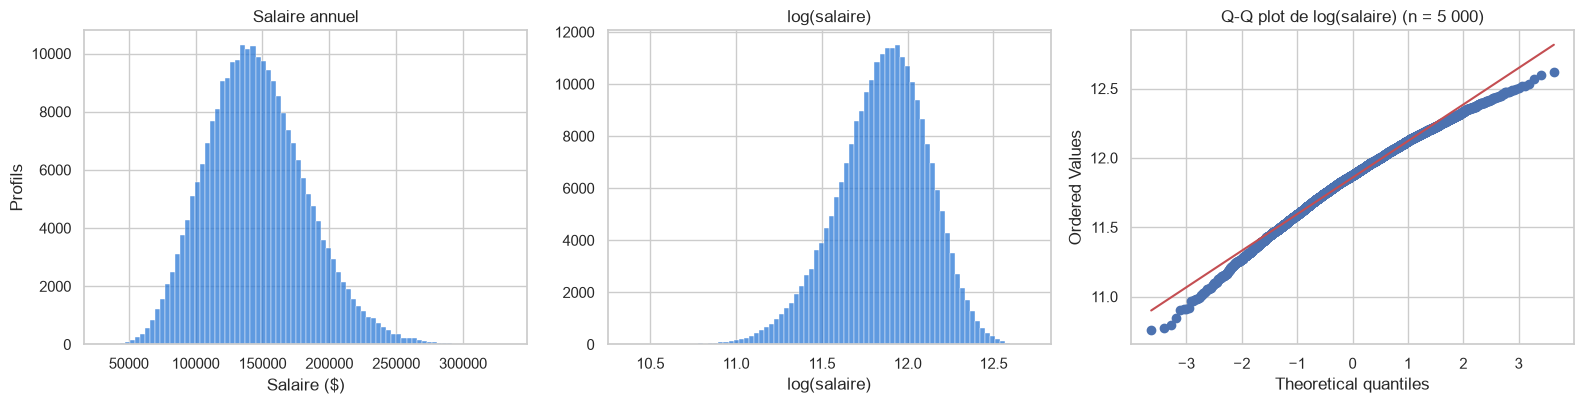

variable,salary,log_salary
n,"250,000.0000","250,000.0000"
mean,"145,718.0805",11.8553
std,"37,407.9527",0.2656
min,"31,867.0000",10.3693
q1,"119,358.0000",11.6899
median,"143,453.0000",11.8738
q3,"169,492.0000",12.0406
max,"333,046.0000",12.7160
skewness,0.3794,-0.3933
excess_kurtosis,0.1509,0.2290


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df.salary, bins=80, color=BLUE, ax=axes[0])
axes[0].set(title="Salaire annuel", xlabel="Salaire ($)", ylabel="Profils")
sns.histplot(np.log(df.salary), bins=80, color=BLUE, ax=axes[1])
axes[1].set(title="log(salaire)", xlabel="log(salaire)", ylabel="")
st.probplot(np.log(df.salary.sample(5000, random_state=cfg.SEED)), dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot de log(salaire) (n = 5 000)")
plt.tight_layout(); plt.show()

sstats.target_summary(df).set_index("variable").T

**Lecture :** le salaire est légèrement asymétrique à droite (skewness ≈ 0,38). Le passage au log le rend plus symétrique, mais pas parfaitement gaussien. Avec n = 250 000, les tests de normalité rejettent H₀ pour d'infimes écarts. On regarde donc surtout la *forme* (histogramme, Q-Q plot) et on double chaque test paramétrique de son équivalent non paramétrique.

## 4. Analyse univariée : équilibre des modalités

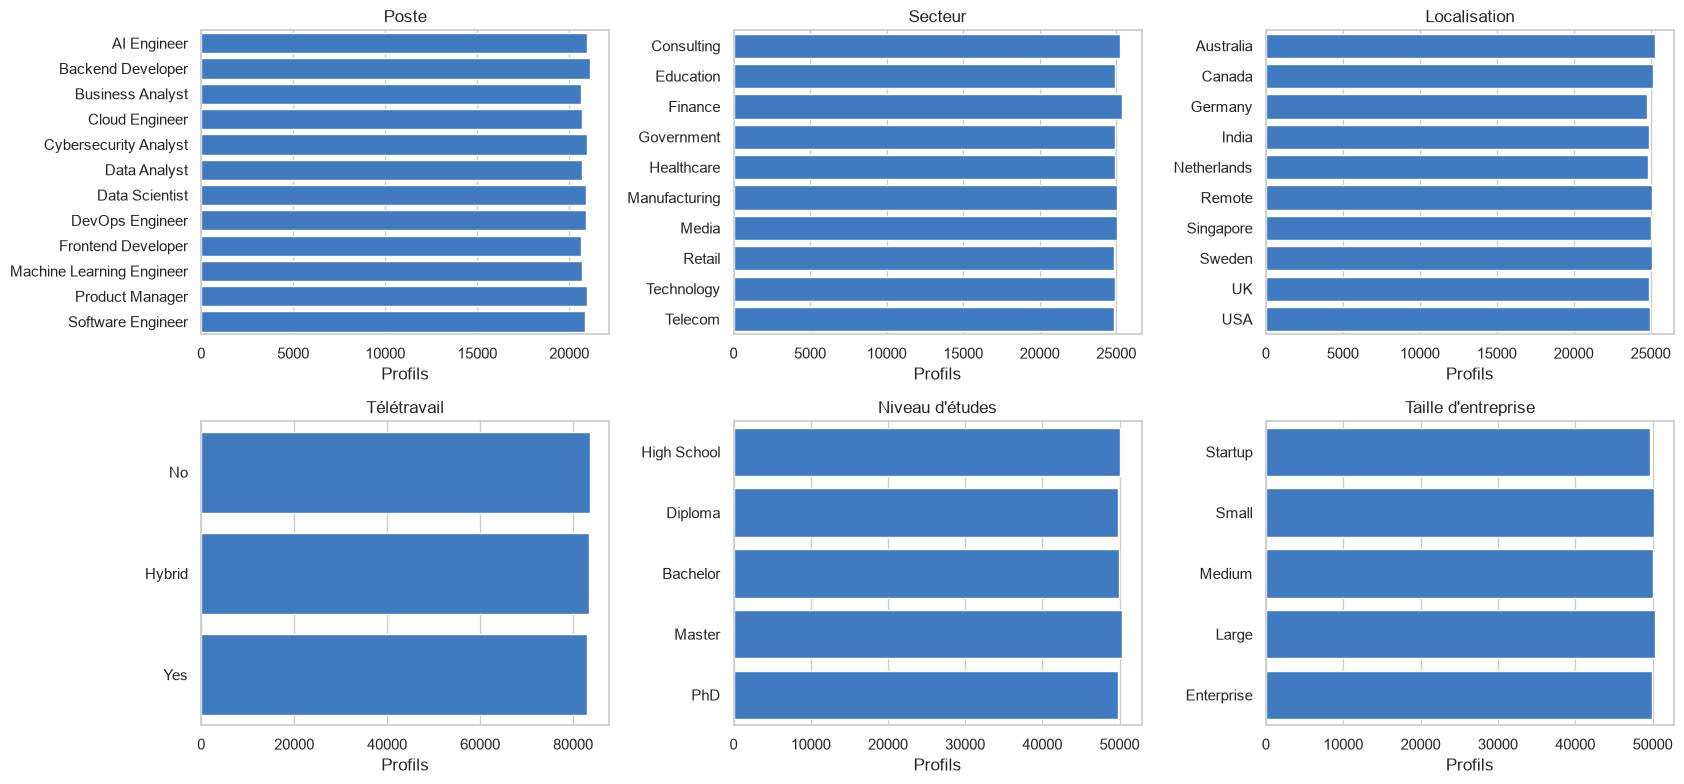

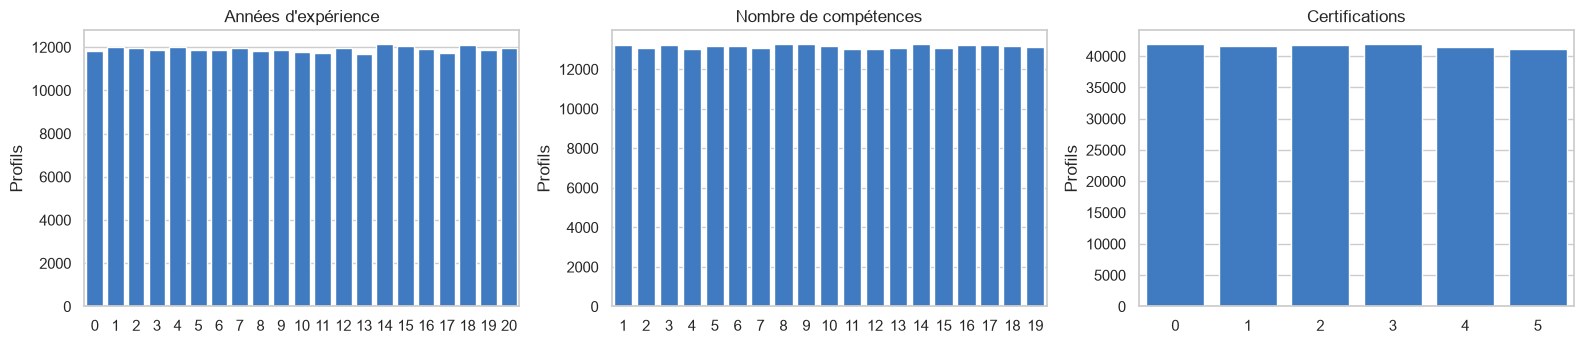

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), cfg.CATEGORICAL, strict=True):
    order = cfg.CATEGORY_LEVELS[c]
    sns.countplot(data=df, y=c, order=order, color=BLUE, ax=ax)
    ax.set(title=L[c], xlabel="Profils", ylabel="")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, c in zip(axes, cfg.NUMERIC, strict=True):
    sns.countplot(data=df, x=c, color=BLUE, ax=ax)
    ax.set(title=L[c], xlabel="", ylabel="Profils")
plt.tight_layout(); plt.show()

**Constat :** toutes les modalités sont presque parfaitement équilibrées (≈ 20 800 profils par métier, ≈ 50 000 par niveau d'études, ≈ 25 000 par pays), et les variables numériques suivent des lois uniformes. Aucun vrai marché du travail ne ressemble à ça. **Le jeu de données est très probablement synthétique**, et cela conditionne toute l'interprétation qui suit.

## 5. Analyse bivariée : salaire selon chaque variable

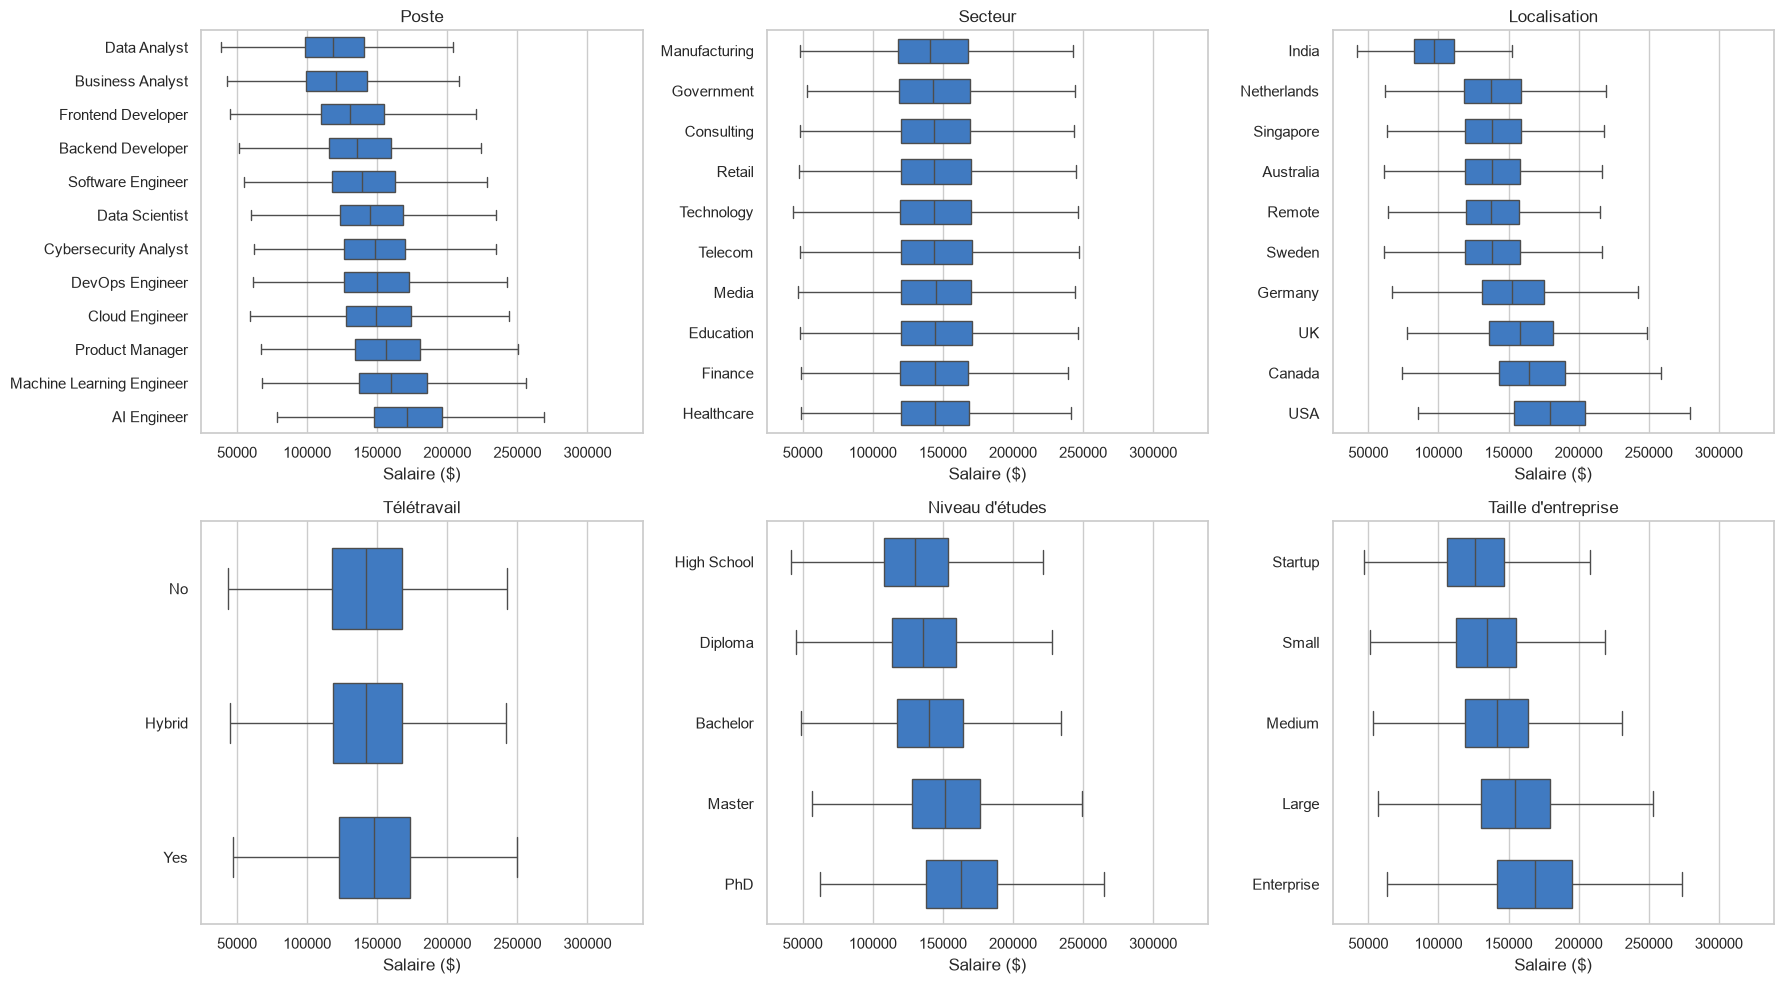

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.ravel(), cfg.CATEGORICAL, strict=True):
    order = (df.groupby(c).salary.median().sort_values().index
             if c in cfg.NOMINAL else cfg.CATEGORY_LEVELS[c])
    sns.boxplot(data=df.sample(40_000, random_state=cfg.SEED), y=c, x="salary", order=order,
                color=BLUE, fliersize=0, ax=ax, width=.6)
    ax.set(title=L[c], xlabel="Salaire ($)", ylabel="")
plt.tight_layout(); plt.show()

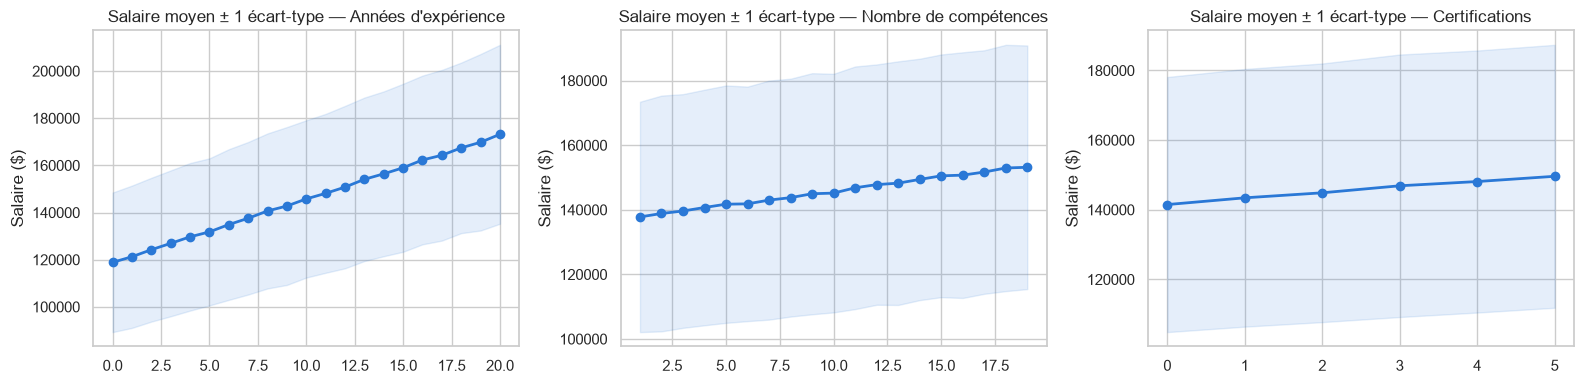

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cfg.NUMERIC, strict=True):
    g = df.groupby(c).salary.agg(["mean", "std"])
    ax.plot(g.index, g["mean"], marker="o", color=BLUE, lw=2)
    ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=BLUE, alpha=.12)
    ax.set(title=f"Salaire moyen ± 1 écart-type — {L[c]}", xlabel="", ylabel="Salaire ($)")
plt.tight_layout(); plt.show()

**Hétéroscédasticité.** La dispersion des salaires grandit avec leur niveau. On le vérifie ci-dessous : écart-type et moyenne sont proportionnels entre les groupes, avec un coefficient de variation à peu près constant. C'est la signature d'un modèle **multiplicatif**, `salaire = base × f(poste) × f(pays) × …`, d'où l'intérêt de travailler en log.

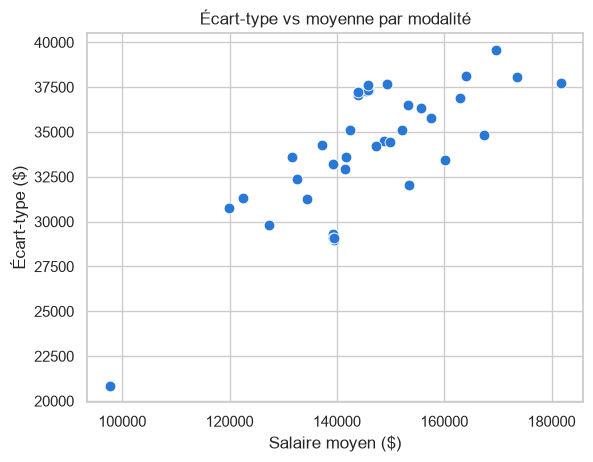

Corrélation moyenne / écart-type entre modalités : 0.712


In [11]:
cv = pd.concat([df.groupby(c).salary.agg(["mean", "std"]).assign(feature=c) for c in cfg.CATEGORICAL])
cv["coef_variation"] = cv["std"] / cv["mean"]
ax = sns.scatterplot(data=cv, x="mean", y="std", color=BLUE, s=60)
ax.set(title="Écart-type vs moyenne par modalité", xlabel="Salaire moyen ($)", ylabel="Écart-type ($)")
plt.show()
print(f"Corrélation moyenne / écart-type entre modalités : {cv['mean'].corr(cv['std']):.3f}")

## 6. Tests statistiques

- **Variables catégorielles → salaire :** ANOVA à un facteur (avec η²), Kruskal-Wallis (avec ε²) et Levene pour l'homogénéité des variances.
- **Variables numériques → salaire :** corrélations de Pearson (IC 95 % par transformation de Fisher) et de Spearman.

Avec n = 250 000, une différence de quelques dollars est « significative ». On juge donc l'importance sur les **tailles d'effet** (seuils de Cohen : η² ≥ 0,01 faible, ≥ 0,06 moyen, ≥ 0,14 fort).

In [12]:
cat_tests = sstats.categorical_tests(df)
cat_tests[["feature", "k_groups", "anova_F", "anova_p", "eta2", "eta2_effect", "kruskal_H",
           "kruskal_p", "epsilon2", "levene_p", "highest", "lowest", "max_gap_means"]]

,feature,k_groups,anova_F,anova_p,eta2,eta2_effect,kruskal_H,kruskal_p,epsilon2,levene_p,highest,lowest,max_gap_means
2,location,10,"13,284.5845",0.0000,0.3235,fort,"77,460.5412",0.0000,0.3098,0.0000,USA,India,"84,025.9017"
5,company_size,5,"12,346.8692",0.0000,0.1650,fort,"38,702.0315",0.0000,0.1548,0.0000,Enterprise,Startup,"42,327.3870"
0,job_title,12,"4,369.7225",0.0000,0.1613,fort,"39,682.4386",0.0000,0.1587,0.0000,AI Engineer,Data Analyst,"53,606.7840"
4,education_level,5,"6,624.7914",0.0000,0.0958,moyen,"23,098.3730",0.0000,0.0924,0.0000,PhD,High School,"32,260.6691"
3,remote_work,3,564.7059,0.0000,0.0045,négligeable,"1,111.0790",0.0000,0.0044,0.0024,Yes,No,"5,347.2889"
1,industry,10,0.7523,0.6610,0.0000,négligeable,6.0133,0.7386,0.0000,0.9956,Education,Retail,593.8651


In [13]:
num_tests = sstats.numeric_correlations(df)
num_tests

,feature,pearson_r,pearson_p,r_ci_low,r_ci_high,r2,spearman_rho,spearman_p,effect,slope_per_unit
0,experience_years,0.4376,0.0000,0.4345,0.4408,0.1915,0.4379,0.0000,moyen,"2,701.1730"
1,skills_count,0.1273,0.0000,0.1234,0.1312,0.0162,0.1252,0.0000,faible,869.0949
2,certifications,0.0738,0.0000,0.0699,0.0777,0.0054,0.0720,0.0000,négligeable,"1,618.1991"


In [14]:
sstats.tukey(df, "education_level")

,feature,group1,group2,meandiff,p-adj,lower,upper,reject
0,education_level,Bachelor,Diploma,"-5,251.9563",0.0000,"-5,866.4607","-4,637.4519",True
1,education_level,Bachelor,High School,"-10,695.1950",0.0000,"-11,308.8104","-10,081.5797",True
2,education_level,Bachelor,Master,"10,894.7765",0.0000,"10,282.0351","11,507.5179",True
3,education_level,Bachelor,PhD,"21,565.4740",0.0000,"20,951.2197","22,179.7283",True
4,education_level,Diploma,High School,"-5,443.2387",0.0000,"-6,057.3908","-4,829.0867",True
5,education_level,Diploma,Master,"16,146.7329",0.0000,"15,533.4541","16,760.0116",True
6,education_level,Diploma,PhD,"26,817.4303",0.0000,"26,202.6399","27,432.2207",True
7,education_level,High School,Master,"21,589.9716",0.0000,"20,977.5836","22,202.3596",True
8,education_level,High School,PhD,"32,260.6691",0.0000,"31,646.7672","32,874.5709",True
9,education_level,Master,PhD,"10,670.6975",0.0000,"10,057.6692","11,283.7257",True


**Lecture :**
- **Effet fort :** la localisation (η² ≈ 0,32), puis la taille d'entreprise et le poste (≈ 0,16).
- **Effet moyen :** le niveau d'études (≈ 0,10), et l'expérience côté variables numériques (r ≈ 0,44).
- **Effets faibles :** les compétences et les certifications.
- **Négligeable :** le télétravail (η² ≈ 0,004).
- **Le secteur d'activité n'a aucun effet** (p ≈ 0,66) : c'est le seul résultat non significatif malgré n = 250 000.
- **Tukey HSD :** les écarts entre tous les niveaux d'études sont significatifs, et la hiérarchie est monotone (Bac < Diplôme < Licence < Master < PhD).

## 7. Indépendance des variables explicatives

Pour mesurer l'association entre deux variables explicatives, on utilise selon leur type :
- **V de Cramér** entre deux catégorielles ;
- **rapport de corrélation η** entre une catégorielle et une numérique ;
- **|ρ| de Spearman** entre deux numériques.

C'est un point clé pour l'analyse causale : si les variables sont indépendantes, aucune n'est un facteur de confusion pour une autre.

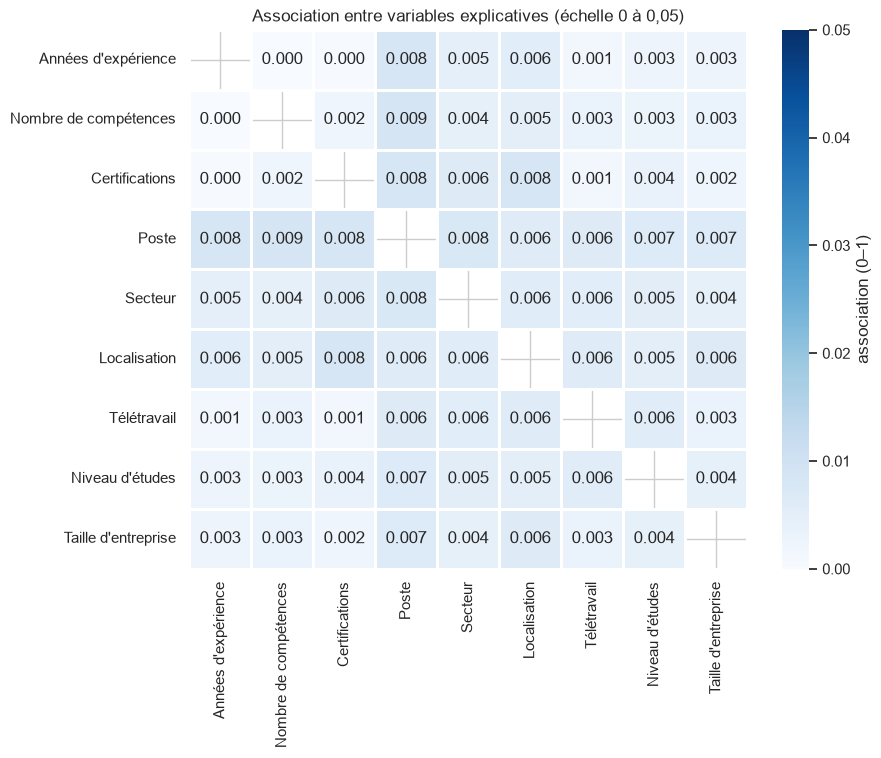

,feature_a,feature_b,measure,value,p_value
9,skills_count,job_title,eta,0.0085,0.0787
17,certifications,location,eta,0.0082,0.0546
2,experience_years,job_title,eta,0.0081,0.1202
15,certifications,job_title,eta,0.0081,0.1240
21,job_title,industry,Cramér V,0.0075,0.0283


In [15]:
assoc, pairs = sstats.feature_associations(df)
mask = np.eye(len(assoc), dtype=bool)
plt.figure(figsize=(9, 7))
sns.heatmap(assoc.rename(index=L, columns=L), mask=mask, cmap="Blues", vmin=0, vmax=.05,
            annot=True, fmt=".3f", linewidths=2, cbar_kws={"label": "association (0–1)"})
plt.title("Association entre variables explicatives (échelle 0 à 0,05)"); plt.show()
pairs.head(5)

**Constat :** l'association maximale est inférieure à 0,01 et aucune paire n'est significative au seuil de 5 %. Les variables explicatives sont **mutuellement indépendantes**, comme dans un plan d'expérience randomisé.

## 8. Modèle log-linéaire : effets « toutes choses égales par ailleurs »

On estime par MCO le modèle `log(salaire) ~ toutes les variables`, avec des erreurs standard robustes HC3. Un coefficient β se lit comme un écart de **exp(β) − 1 en %** par rapport à la modalité de référence. La décomposition ANOVA de type II donne la part de variance expliquée par chaque variable.

In [16]:
coefs, aov, summary = sstats.log_linear_model(df)
print(json.dumps(summary, indent=2, default=float))
aov[["feature", "df", "F", "partial_eta2", "share_explained_pct"]]

{
  "r2": 0.9729222375039732,
  "adj_r2": 0.9729176876573002,
  "n": 250000,
  "aic": -855665.7363206195,
  "bic": -855217.2800241552,
  "residual_std_log": 0.04370223655468898
}


,feature,df,F,partial_eta2,share_explained_pct
2,location,9.0000,"360,560.0208",0.9285,36.1217
6,experience_years,1.0000,"1,742,554.5362",0.8746,19.3970
0,job_title,11.0000,"138,119.4844",0.8587,16.9120
5,company_size,4.0000,"346,781.1641",0.8473,15.4406
4,education_level,4.0000,"212,826.9251",0.7730,9.4762
7,skills_count,1.0000,"146,226.9279",0.3691,1.6277
8,certifications,1.0000,"50,366.4251",0.1677,0.5606
3,remote_work,2.0000,"20,850.7847",0.1430,0.4642
1,industry,9.0000,0.7316,0.0000,0.0001


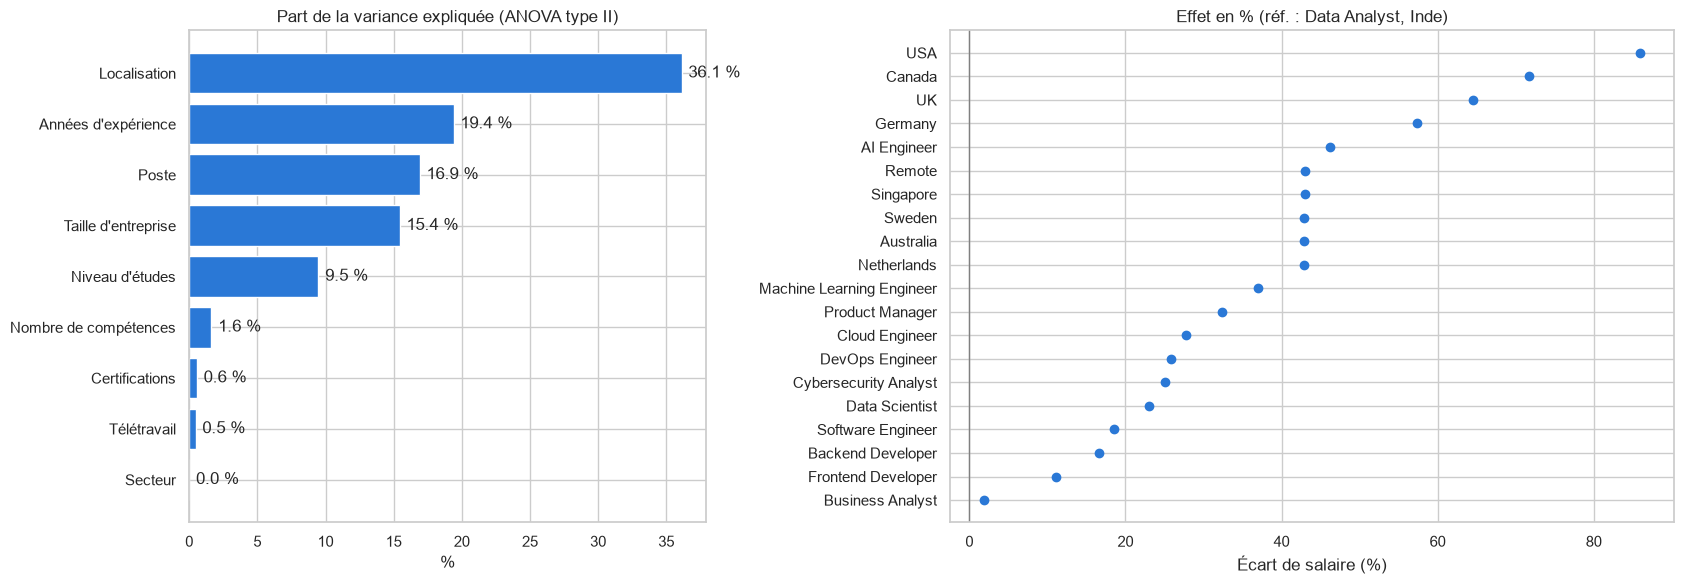

,feature,level,pct_effect,pct_ci_low,pct_ci_high,p_value
0,Intercept,NaN,"4,657,340.8580","4,650,084.6200","4,664,608.4190",0.0000
1,job_title,AI Engineer,46.1790,46.0370,46.3220,0.0000
2,job_title,Backend Developer,16.6690,16.5540,16.7830,0.0000
3,job_title,Business Analyst,1.8750,1.7620,1.9880,0.0000
4,job_title,Cloud Engineer,27.7170,27.5950,27.8390,0.0000
5,job_title,Cybersecurity Analyst,25.0050,24.8860,25.1240,0.0000
6,job_title,Data Scientist,23.0590,22.9410,23.1770,0.0000
7,job_title,DevOps Engineer,25.8300,25.7090,25.9510,0.0000
8,job_title,Frontend Developer,11.0810,10.9680,11.1950,0.0000
9,job_title,Machine Learning Engineer,36.9290,36.7970,37.0600,0.0000


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.4]})
a = aov.sort_values("share_explained_pct")
axes[0].barh(a.feature.map(L), a.share_explained_pct, color=BLUE)
axes[0].set(title="Part de la variance expliquée (ANOVA type II)", xlabel="%")
for y, v in enumerate(a.share_explained_pct):
    axes[0].text(v + .5, y, f"{v:.1f} %", va="center")
c = coefs[coefs.feature.isin(["location", "job_title"])].sort_values("pct_effect")
axes[1].errorbar(c.pct_effect, c.level, xerr=[c.pct_effect - c.pct_ci_low, c.pct_ci_high - c.pct_effect],
                 fmt="o", color=BLUE)
axes[1].axvline(0, color="grey", lw=1)
axes[1].set(title="Effet en % (réf. : Data Analyst, Inde)", xlabel="Écart de salaire (%)")
plt.tight_layout(); plt.show()
coefs[["feature", "level", "pct_effect", "pct_ci_low", "pct_ci_high", "p_value"]].round(3)

In [18]:
sep = sstats.separability_tests(df)
sep

,interaction,F,p_value,df_added,delta_r2
0,experience_years:C(job_title),"2,121.5725",0.0000,11.0000,0.0023
1,C(education_level):C(job_title),164.4117,0.0000,44.0000,0.0008
2,C(location):C(job_title),0.0000,1.0000,99.0000,-0.0002
3,experience_years:C(education_level),"2,981.5389",0.0000,4.0000,0.0012


**Lecture :**
- Le modèle log-linéaire explique **97,3 %** de la variance de log(salaire). Le bruit résiduel est d'environ ±4,5 %.
- **Décomposition :** localisation 36 %, expérience 19 %, poste 17 %, taille d'entreprise 15 %, études 9 %. Compétences, certifications et télétravail pèsent moins de 2 % chacun ; le secteur, 0 %.
- **Exemples d'effets :** les États-Unis paient environ +86 % par rapport à l'Inde, un AI Engineer environ +46 % par rapport à un Data Analyst, et chaque année d'expérience rapporte environ +1,9 %.
- **Le modèle n'est pas purement multiplicatif.** Les interactions expérience × poste et expérience × études sont significatives, avec un gain de R² modeste (+0,1 à 0,2 point). L'interaction pays × poste, elle, n'apporte rien. Ce petit gain non linéaire est ce que les modèles de boosting peuvent capter en plus.

## 9. Analyse causale

**Question :** quel serait l'effet sur le salaire de changer *une seule* caractéristique, tout le reste égal par ailleurs ?

**Démarche** (DoWhy : modéliser → identifier → estimer → réfuter) :
1. **Graphe causal (DAG) :** chaque variable est une cause directe du salaire et aucune ne cause les autres. L'implication testable, l'indépendance deux à deux, est vérifiée (section 7).
2. **Identification :** critère backdoor. L'ensemble d'ajustement est formé de toutes les autres variables.
3. **Estimation :** quatre estimateurs comparés.
   - différence naïve ;
   - régression ajustée (DoWhy) ;
   - pondération par score de propension, IPW (traitements binaires) ;
   - **Double Machine Learning** (EconML `LinearDML`, modèles de nuisance LightGBM, cross-fitting).
4. **Réfutation :** traitement placebo, cause commune aléatoire, sous-échantillon à 80 %.
5. **Hétérogénéité (CATE) :** effet selon le pays et selon le métier.

Les calculs (≈ 10 min) sont faits par `python -m salary.causal` sur un échantillon de 80 000 profils. On lit ici leurs résultats.

In [19]:
from salary.causal import dag_dot
print(dag_dot())

digraph {
  rankdir=LR;
  node [shape=box, style="rounded"];
  "experience_years" -> "salary";
  "skills_count" -> "salary";
  "certifications" -> "salary";
  "job_title" -> "salary";
  "industry" -> "salary";
  "location" -> "salary";
  "remote_work" -> "salary";
  "education_level" -> "salary";
  "company_size" -> "salary";
}


In [20]:
ate = pd.read_csv(cfg.REPORTS_DIR / "causal" / "ate.csv")
ate[["label", "n", "naive_effect", "ols_effect", "ipw_effect", "dml_effect", "dml_ci_low",
     "dml_ci_high", "naive_pct", "dml_pct"]].round(2)

,label,n,naive_effect,ols_effect,ipw_effect,dml_effect,dml_ci_low,dml_ci_high,naive_pct,dml_pct
0,Master/PhD vs ≤ Licence,80000,"21,343.1400","21,469.8800","21,450.2400","21,463.2600","21,353.4200","21,573.1000",16.0200,16.1000
1,Grande entreprise (Large/Enterprise) vs autres,80000,"28,136.5700","28,205.5300","28,194.6300","28,127.3900","27,994.6200","28,260.1500",20.9500,20.9700
2,Télétravail total vs présentiel,53389,"5,565.5400","5,317.5100","5,325.1400","5,346.3700","5,254.7700","5,437.9700",4.0100,3.8500
3,+1 année d'expérience,80000,"2,678.8400","2,690.3300",NaN,"2,685.0700","2,677.3400","2,692.8000",1.9100,1.9200
4,+1 certification,80000,"1,631.5400","1,611.3500",NaN,"1,620.4600","1,598.6300","1,642.2800",1.1700,1.1500
5,+1 compétence,80000,875.4100,860.0100,NaN,855.6900,848.8400,862.5500,0.6200,0.6100


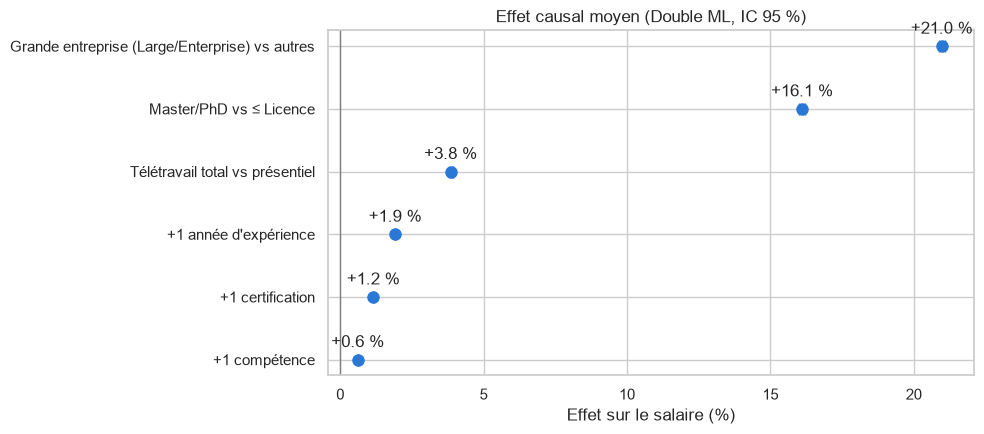

In [21]:
d = ate.sort_values("dml_pct")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(d.dml_pct, d.label, xerr=[d.dml_pct - d.dml_pct_ci_low, d.dml_pct_ci_high - d.dml_pct],
            fmt="o", color=BLUE, ms=8, capsize=4)
for x, y in zip(d.dml_pct, d.label, strict=True):
    ax.annotate(f"{x:+.1f} %", (x, y), textcoords="offset points", xytext=(0, 9), ha="center")
ax.axvline(0, color="grey", lw=1)
ax.set(title="Effet causal moyen (Double ML, IC 95 %)", xlabel="Effet sur le salaire (%)")
plt.tight_layout(); plt.show()

In [22]:
refs = pd.read_csv(cfg.REPORTS_DIR / "causal" / "refutations.csv")
refs.pivot(index="treatment", columns="refuter", values="new_effect").join(
    ate.set_index("treatment")["ols_effect"]).round(1)

,data_subset_refuter,placebo_treatment_refuter,random_common_cause,ols_effect
treatment,,,,
certifications,"1,609.5000",7.8000,"1,611.3000","1,611.3000"
education_advanced,"21,453.4000",-3.9000,"21,469.9000","21,469.9000"
experience_years,"2,689.6000",-4.9000,"2,690.3000","2,690.3000"
large_company,"28,218.9000",-1.2000,"28,205.6000","28,205.5000"
remote_yes,"5,319.3000",-9.3000,"5,317.5000","5,317.5000"
skills_count,860.4000,-0.1000,860.0000,860.0000


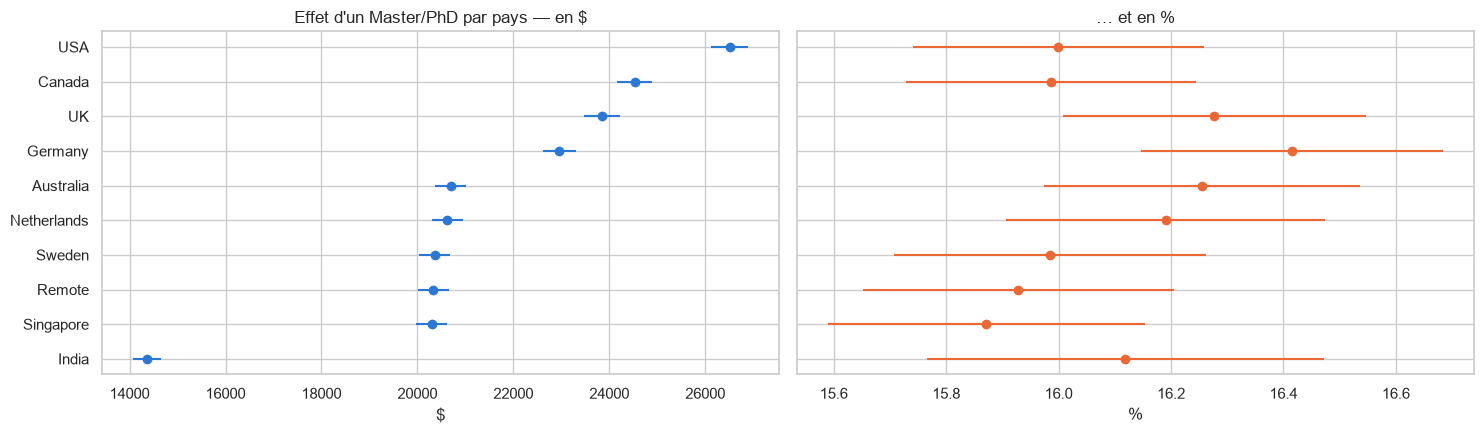

effet_min   effet_max  pct_min  pct_max
treatment          by                                                 
education_advanced job_title 21,145.8000 21,710.1000  13.1000  19.8000
                   location  14,358.5000 26,510.1000  15.9000  16.4000
experience_years   job_title  2,665.9000  2,708.9000   1.6000   2.3000
                   location   1,791.5000  3,350.5000   1.9000   1.9000
large_company      job_title 23,344.1000 33,096.5000  20.7000  21.4000
                   location  19,141.5000 34,844.0000  20.8000  21.3000

In [23]:
cate = pd.read_csv(cfg.REPORTS_DIR / "causal" / "cate.csv")
d = cate[(cate.treatment == "education_advanced") & (cate.by == "location")].sort_values("effect")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
axes[0].errorbar(d.effect, d.level, xerr=[d.effect - d.ci_low, d.ci_high - d.effect], fmt="o", color=BLUE)
axes[0].set(title="Effet d'un Master/PhD par pays — en $", xlabel="$")
axes[1].errorbar(d.effect_pct, d.level, xerr=[d.effect_pct - d.pct_ci_low, d.pct_ci_high - d.effect_pct],
                 fmt="o", color=ORANGE)
axes[1].set(title="… et en %", xlabel="%")
plt.tight_layout(); plt.show()
cate.groupby(["treatment", "by"]).agg(effet_min=("effect", "min"), effet_max=("effect", "max"),
                                      pct_min=("effect_pct", "min"), pct_max=("effect_pct", "max")).round(1)

**Lecture :**
- **Les quatre estimateurs concordent** (écart de 4 % au plus, sur le télétravail). L'ajustement ne change presque rien, ce qui est cohérent avec l'absence de confusion. Sur des données observationnelles réelles, cet écart entre estimation naïve et ajustée mesurerait précisément le biais de confusion.
- **Tous les tests de réfutation passent :**
  - avec un placebo, l'effet tombe à ≈ 0 ;
  - avec une cause commune aléatoire ou un sous-échantillon, l'effet reste inchangé.
- **Hétérogénéité :** en dollars, l'effet d'un Master/PhD varie fortement selon le pays (il est bien plus élevé aux USA qu'en Inde). En pourcentage, il est quasi constant (≈ +16 %). L'effet causal est donc **multiplicatif**.
- ⚠️ Ces effets décrivent le **générateur des données synthétiques**, pas le marché réel. Dans la réalité, études, poste et pays sont liés entre eux, et il faudrait un vrai travail d'identification (variables instrumentales, discontinuités, données de panel…).

## 10. Modèles de machine learning

**Protocole** (`python -m salary.train`) :
- **Découpage :** 80/20 stratifié par métier, graine 42. Le jeu de test ne sert qu'au rapport final.
- **Cible :** log(salaire), car la structure est multiplicative. Les métriques sont calculées en dollars.
- **Modèles :**
  - baseline (médiane) et Ridge log-linéaire ;
  - Random Forest ;
  - **XGBoost, LightGBM, CatBoost** (CatBoost traite nativement les catégories) ;
  - ensemble des trois boosters (moyenne géométrique).
- **Réglage :** Optuna, 20 essais par booster, en validation croisée à 3 plis sur 50 000 lignes d'entraînement.
- **Évaluation :** validation croisée à 5 plis sur tout l'entraînement. **Le modèle est sélectionné sur la CV**, jamais sur le test.
- **Intervalles de prédiction à 80 % :** régression quantile LightGBM, **conformalisée** sur 15 % de l'entraînement mis de côté (couverture garantie).

In [24]:
m = json.loads((cfg.MODELS_DIR / "metrics.json").read_text())
rows = []
for k, r in m["models"].items():
    rows.append({"modèle": r["display_name"], "CV RMSE": r["cv"]["rmse_mean"], "± CV": r["cv"]["rmse_std"],
                 "test RMSE": r["test"]["rmse"], "test MAE": r["test"]["mae"], "MAPE %": r["test"]["mape"],
                 "R²": r["test"]["r2"], "±10 % (%)": r["test"]["within_10pct"],
                 "écart test−train": r["overfit_gap_rmse"], "fit (s)": r["fit_time_s"]})
res = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
print("Modèle retenu (meilleure CV) :", m["best_model"])
print("Intervalle 80 % :", {k: round(v, 1) if isinstance(v, float) else v for k, v in m["interval"].items()})
res

Modèle retenu (meilleure CV) : catboost
Intervalle 80 % : {'alpha_low': 0.1, 'alpha_high': 0.9, 'target_coverage': 80.0, 'conformal_offset': 142.9, 'raw': {'coverage': 79.278, 'mean_width': 14223.56683390428}, 'coverage': 80.2, 'mean_width': 14509.4}


,modèle,CV RMSE,± CV,test RMSE,test MAE,MAPE %,R²,±10 % (%),écart test−train,fit (s)
0,CatBoost,"5,031.8297",22.0124,"5,016.9891","4,004.9322",2.9488,0.9820,98.3140,10.1181,43.3495
1,Ensemble (moyenne des boosters),"5,038.9956",21.2631,"5,024.0353","4,012.2197",2.9546,0.9820,98.2580,30.7604,57.6323
2,LightGBM,"5,102.7306",24.4770,"5,084.7607","4,061.0649",2.9881,0.9816,98.1820,54.7449,10.7951
3,XGBoost,"5,110.7018",18.6086,"5,097.4114","4,070.4634",2.9927,0.9815,98.1880,29.0473,3.4877
4,Ridge (log-linéaire),"5,867.4136",22.4391,"5,861.5777","4,609.4682",3.3488,0.9755,97.0720,-4.6689,0.3380
5,Random Forest,"9,069.7216",62.0056,"8,641.2961","6,747.1427",4.8127,0.9467,90.2700,733.6763,9.9486
6,Baseline (médiane),"37,469.3709",146.1171,"37,519.9292","29,797.5550",22.2957,-0.0045,29.9800,50.5327,0.2116


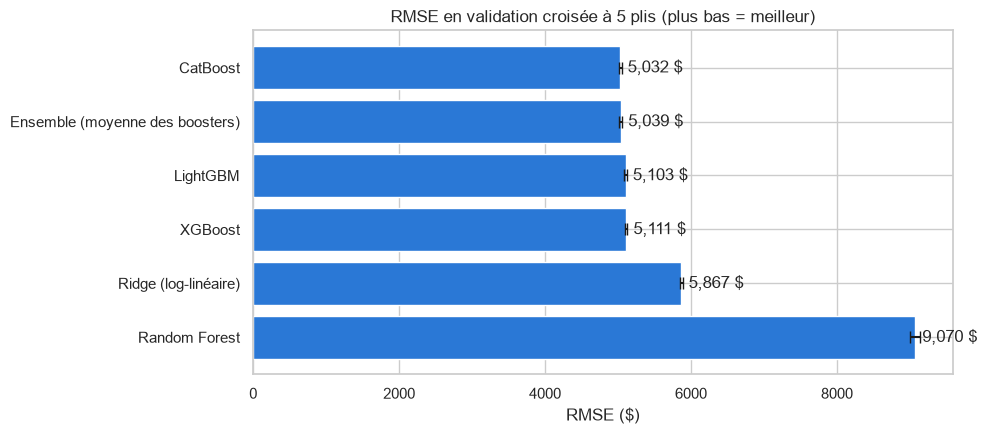

In [25]:
r = res[res["modèle"] != "Baseline (médiane)"].sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(r["modèle"], r["CV RMSE"], xerr=r["± CV"], color=BLUE, capsize=4)
for y, v in enumerate(r["CV RMSE"]):
    ax.text(v + 100, y, f"{v:,.0f} $", va="center")
ax.set(title="RMSE en validation croisée à 5 plis (plus bas = meilleur)", xlabel="RMSE ($)")
plt.tight_layout(); plt.show()

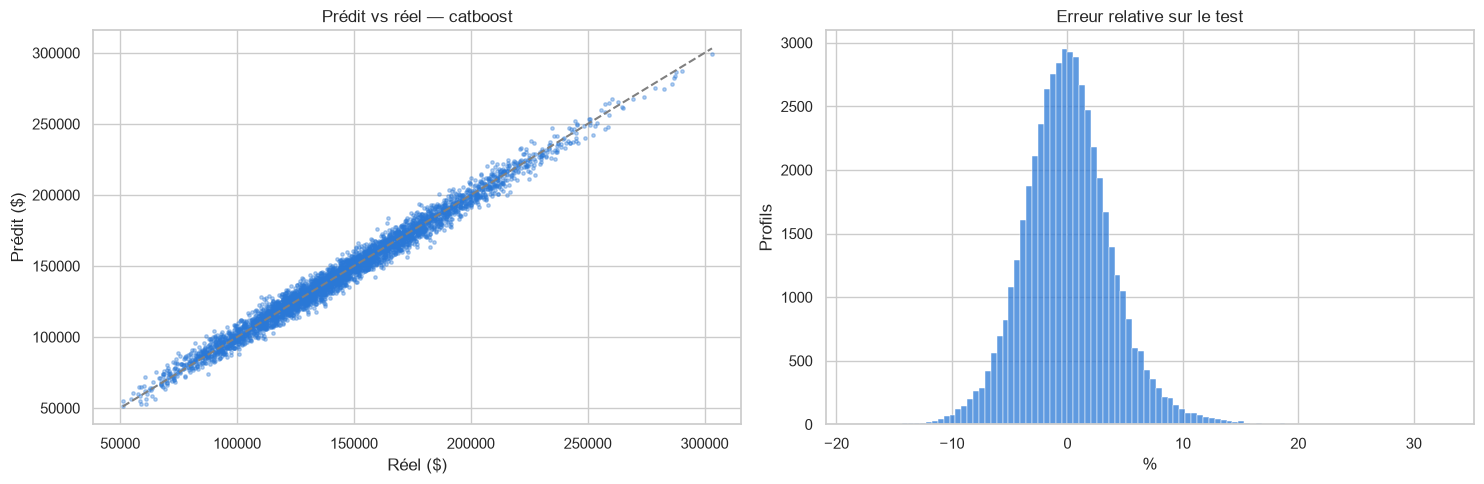

count   50,000.0000
mean         2.9500
std          2.4800
min          0.0000
50%          2.3600
80%          4.6500
95%          7.7100
max         32.6700
dtype: float64


In [26]:
preds = pd.read_parquet(cfg.REPORTS_DIR / "models" / "predictions_test.parquet")
best = m["best_model"]
s = preds.sample(4000, random_state=cfg.SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(s.salary, s[f"pred_{best}"], s=6, alpha=.35, color=BLUE)
lim = [s.salary.min(), s.salary.max()]
axes[0].plot(lim, lim, "--", color="grey")
axes[0].set(title=f"Prédit vs réel — {best}", xlabel="Réel ($)", ylabel="Prédit ($)")
rel = (preds[f"pred_{best}"] - preds.salary) / preds.salary * 100
sns.histplot(rel, bins=100, color=BLUE, ax=axes[1])
axes[1].set(title="Erreur relative sur le test", xlabel="%", ylabel="Profils")
plt.tight_layout(); plt.show()
print(rel.abs().describe(percentiles=[.5, .8, .95]).round(2))

In [27]:
seg = pd.read_csv(cfg.REPORTS_DIR / "models" / "segment_errors.csv")
seg.pivot_table(index="segment", columns="feature", values="mape").round(2)

feature,company_size,education_level,industry,job_title,location,remote_work
segment,,,,,,
AI Engineer,NaN,NaN,NaN,2.4400,NaN,NaN
Australia,NaN,NaN,NaN,NaN,3.1200,NaN
Bachelor,NaN,2.9500,NaN,NaN,NaN,NaN
Backend Developer,NaN,NaN,NaN,3.0900,NaN,NaN
Business Analyst,NaN,NaN,NaN,3.5000,NaN,NaN
Canada,NaN,NaN,NaN,NaN,2.4500,NaN
Cloud Engineer,NaN,NaN,NaN,2.7700,NaN,NaN
Consulting,NaN,NaN,3.0100,NaN,NaN,NaN
Cybersecurity Analyst,NaN,NaN,NaN,2.8200,NaN,NaN


**Lecture :**
- **Les trois boosters battent nettement la baseline et la Random Forest.** Ils font aussi mieux que le très bon modèle Ridge log-linéaire, parce qu'ils captent les interactions (expérience × poste, expérience × études) vues en section 8.
- **La Random Forest est en retrait.** Elle moyenne des arbres sur des codes ordinaux et capte mal la structure multiplicative.
- **L'erreur restante est du bruit :** environ 4 à 5 % de bruit multiplicatif non expliqué par les variables, donc une limite basse pour tout modèle.
- **Pas de segment problématique :** l'erreur relative est homogène entre métiers et pays.
- **Pas de surapprentissage notable :** l'écart entre RMSE de test et d'entraînement reste faible.

## 11. Explicabilité (SHAP)

Le modèle prédit log(salaire), donc les valeurs SHAP sont additives en log : `log(prédiction) = base + Σ φᵢ`. Autrement dit, `exp(φᵢ)` est l'effet **multiplicatif** de la variable *i* sur le salaire prédit.

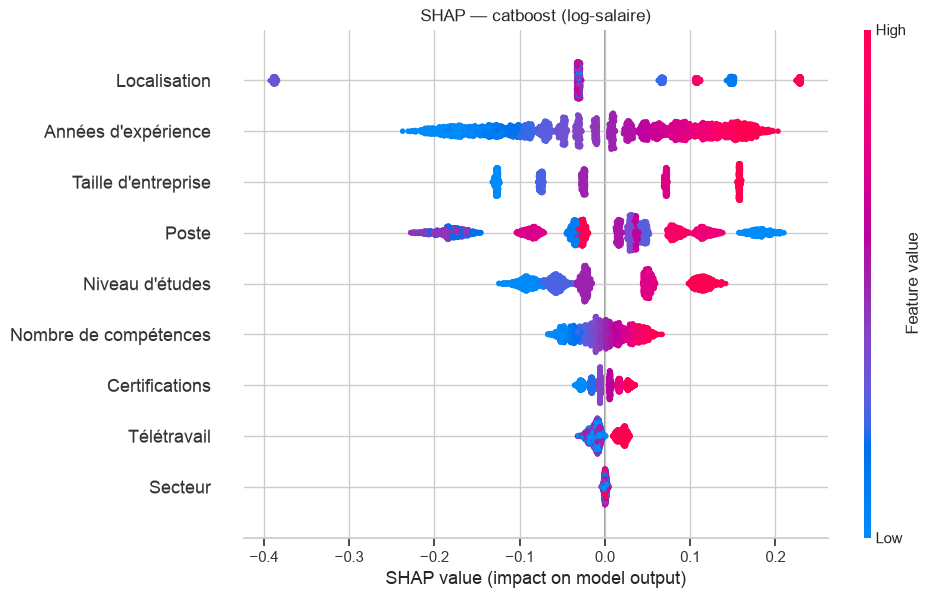

,feature,mean_abs_shap,mean_pct_effect
0,location,0.1105,11.6871
1,experience_years,0.0996,10.4714
2,company_size,0.0911,9.5371
3,job_title,0.0845,8.8180
4,education_level,0.0687,7.1117
5,skills_count,0.0274,2.7801
6,certifications,0.0171,1.7292
7,remote_work,0.0145,1.4636
8,industry,0.0011,0.1131


In [28]:
import shap

from salary.features import make_preprocessor

sv = pd.read_parquet(cfg.REPORTS_DIR / "models" / "shap_sample.parquet")
X = sv[cfg.FEATURES]
values = sv[[f"shap_{f}" for f in cfg.FEATURES]].to_numpy()
X_enc = make_preprocessor("tree").fit(df[cfg.FEATURES]).transform(X)[cfg.FEATURES]
shap.summary_plot(values, X_enc.rename(columns=L), show=False, plot_size=(10, 6))
plt.title(f"SHAP — {m['shap_model']} (log-salaire)"); plt.show()
pd.read_csv(cfg.REPORTS_DIR / "models" / "shap_importance.csv")

**Lecture :** la hiérarchie SHAP (localisation, expérience, poste, taille d'entreprise, études, puis le reste) reproduit celle de l'ANOVA et des effets causaux. Cette concordance n'est garantie **que parce que les variables sont indépendantes**. Sur des données réelles corrélées, SHAP explique le *modèle* et ne mesure pas un effet causal.

## 12. Conclusions

1. **Données** : 250 000 profils propres, équilibrés, aux variables indépendantes, donc presque certainement synthétiques.
2. **Déterminants du salaire** : localisation ≫ expérience ≈ poste ≈ taille d'entreprise > études ≫ compétences, certifications, télétravail ; le secteur n'a aucun effet.
3. **Structure** : essentiellement multiplicative (log-linéaire, R² = 0,973), plus de légères interactions avec l'expérience.
4. **Causalité** : effets robustes aux réfutations, constants en %, et identiques à l'estimation naïve car il n'y a pas de confusion. Par exemple, un Master/PhD rapporte environ +16 % et chaque année d'expérience environ +1,9 %.
5. **Modèles** : les boosters réglés par Optuna atteignent R² ≈ 0,98 et une MAPE d'environ 3 %. Le bruit irréductible fixe la limite. Les intervalles conformalisés couvrent 80 % des cas comme visé.
6. **Mise en production** : application Streamlit (`app/`) avec prédiction, intervalles et explication SHAP, en thème clair ou sombre.